# Population of the states

We will import a new dataset containing population information for each Brazilian state, which will subsequently allow us to determine the per capita emissions for each state.

ℹ
The data was obtained from the [IBGE census](https://www.ibge.gov.br/estatisticas/sociais/saude/22827-censo-demografico-2022.html?=&t=resultados).

In [1]:
import pandas as pd

In [16]:
emissions_per_year = pd.read_csv('/content/emissions_per_year.csv')

In [17]:
states_population = pd.read_excel('/content/drive/MyDrive/Collab Notebooks - Alura/Pandas Course/part_3_pandas_selecting_and_grouping/resources/POP2022_Municipios.xls', header=1, skipfooter=34)
states_population

,UF,COD. UF,COD. MUNIC,NOME DO MUNICÍPIO,POPULAÇÃO
0,RO,11,15,Alta Floresta D'Oeste,21558
1,RO,11,23,Ariquemes,100896
2,RO,11,31,Cabixi,5107
3,RO,11,49,Cacoal,92202
4,RO,11,56,Cerejeiras,15237
...,...,...,...,...,...
5565,GO,52,22005,Vianópolis,14046
5566,GO,52,22054,Vicentinópolis,8776
5567,GO,52,22203,Vila Boa,3686
5568,GO,52,22302,Vila Propício,5646


Since the information pertains to municipalities, we will perform an aggregation based on the state column.

In [18]:
states_population.groupby('UF').sum(numeric_only=True)

,COD. UF,COD. MUNIC
UF,,
AC,264,7719
AL,2754,487914
AM,806,134451
AP,256,5908
BA,12093,7151757
CE,4232,1295156
DF,53,108
ES,2496,226710
GO,12792,2788737


We noticed that the population information has not been aggregated; therefore, some processing of this column will be required to return the data correctly.

In [19]:
states_population['POPULAÇÃO'].astype(int)

ValueError: invalid literal for int() with base 10: '461.748(1)'

In [20]:
states_population[states_population['POPULAÇÃO'].str.contains('\(', na=False)]

<>:1: SyntaxWarning: invalid escape sequence '\('
<>:1: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1686/2851121331.py:1: SyntaxWarning: invalid escape sequence '\('
  states_population[states_population['POPULAÇÃO'].str.contains('\(', na=False)]


,UF,COD. UF,COD. MUNIC,NOME DO MUNICÍPIO,POPULAÇÃO
16,RO,11,205,Porto Velho,461.748(1)
74,AM,13,29,Alvarães,15.916(2)
81,AM,13,409,Barcelos,18.399(3)
83,AM,13,607,Benjamin Constant,37.436(4)
87,AM,13,805,Borba,33.209(5)
88,AM,13,839,Caapiranga,13.851(6)
97,AM,13,1605,Fonte Boa,27.692(7)
98,AM,13,1654,Guajará,13.809(8)
99,AM,13,1704,Humaitá,59.504(9)
103,AM,13,1951,Itamarati,10.783(10)


In [21]:
states_population = states_population.assign(population_without_parentheses = \
                                             states_population['POPULAÇÃO'].replace('\(\d{1,2}\)', '', regex=True), population = \
                                             lambda x: x.loc[:, 'population_without_parentheses'].replace('\.', '', regex=True))


<>:2: SyntaxWarning: invalid escape sequence '\('
<>:3: SyntaxWarning: invalid escape sequence '\.'
<>:2: SyntaxWarning: invalid escape sequence '\('
<>:3: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_1686/857273208.py:2: SyntaxWarning: invalid escape sequence '\('
  states_population['POPULAÇÃO'].replace('\(\d{1,2}\)', '', regex=True), population = \
/tmp/ipykernel_1686/857273208.py:3: SyntaxWarning: invalid escape sequence '\.'
  lambda x: x.loc[:, 'population_without_parentheses'].replace('\.', '', regex=True))


In [22]:
states_population[states_population['POPULAÇÃO'].str.contains('\(', na=False)]

<>:1: SyntaxWarning: invalid escape sequence '\('
<>:1: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1686/2851121331.py:1: SyntaxWarning: invalid escape sequence '\('
  states_population[states_population['POPULAÇÃO'].str.contains('\(', na=False)]


,UF,COD. UF,COD. MUNIC,NOME DO MUNICÍPIO,POPULAÇÃO,population_without_parentheses,population
16,RO,11,205,Porto Velho,461.748(1),461.748,461748
74,AM,13,29,Alvarães,15.916(2),15.916,15916
81,AM,13,409,Barcelos,18.399(3),18.399,18399
83,AM,13,607,Benjamin Constant,37.436(4),37.436,37436
87,AM,13,805,Borba,33.209(5),33.209,33209
88,AM,13,839,Caapiranga,13.851(6),13.851,13851
97,AM,13,1605,Fonte Boa,27.692(7),27.692,27692
98,AM,13,1654,Guajará,13.809(8),13.809,13809
99,AM,13,1704,Humaitá,59.504(9),59.504,59504
103,AM,13,1951,Itamarati,10.783(10),10.783,10783


In [23]:
states_population = states_population.astype({'population': 'int64'})

In [24]:
states_population = states_population.groupby('UF')[['population']].sum().reset_index()
states_population

,UF,population
0,AC,829780
1,AL,3125254
2,AM,3952262
3,AP,774268
4,BA,14659023
5,CE,8936431
6,DF,2923369
7,ES,3975100
8,GO,6950976
9,MA,6800605


## Combining the data

With the information processed, we can join the emissions data with the population data using the [`merge()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html) method.

In [27]:
states_emissions = emissions_per_year[emissions_per_year['Year'] == 2021].groupby('Estado')[['Emission']].sum().reset_index()
states_emissions


,Estado,Emission
0,AC,1.647780e+08
1,AL,6.397182e+07
2,AM,-3.536316e+08
3,AP,-1.464334e+08
4,BA,3.005179e+08
5,BR,0.000000e+00
6,CE,1.575001e+08
7,DF,5.303907e+07
8,ES,2.373097e+08
9,GO,3.138403e+08


In [29]:
grouped_data = pd.merge(states_emissions, states_population, left_on='Estado', right_on='UF')
grouped_data

,Estado,Emission,UF,population
0,AC,1.647780e+08,AC,829780
1,AL,6.397182e+07,AL,3125254
2,AM,-3.536316e+08,AM,3952262
3,AP,-1.464334e+08,AP,774268
4,BA,3.005179e+08,BA,14659023
5,CE,1.575001e+08,CE,8936431
6,DF,5.303907e+07,DF,2923369
7,ES,2.373097e+08,ES,3975100
8,GO,3.138403e+08,GO,6950976
9,MA,5.491927e+08,MA,6800605


Let’s check whether there is any indication that emissions increase as the population size grows.

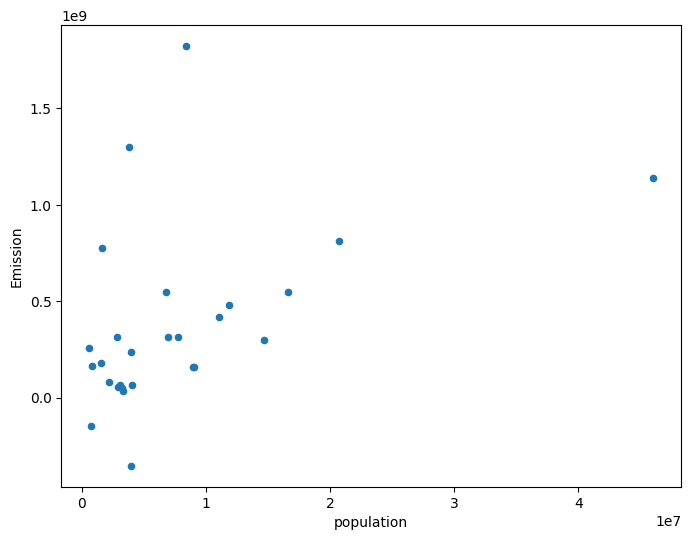

In [31]:
grouped_data.plot(x = 'population', y = 'Emission', kind = 'scatter', figsize=(8,6));

If we want to know the information for each state at the points on the graph, we can use a different library to create a more elaborate graph.

In [32]:
import plotly.express as px

In [33]:
px.scatter(data_frame = grouped_data, x = 'population', y = 'Emission', text='Estado', opacity=0)

To obtain per capita emissions, we will create a new column by dividing the emission values ​​by the population of each state.

In [34]:
grouped_data =  grouped_data.assign(emission_per_capita = grouped_data['Emission'] / grouped_data['population']).sort_values('emission_per_capita', ascending=False)
grouped_data

,Estado,Emission,UF,population,emission_per_capita
20,RO,7.781357e+08,RO,1616379,481.406685
21,RR,2.553918e+08,RR,634805,402.315342
12,MT,1.299280e+09,MT,3784239,343.339916
13,PA,1.824634e+09,PA,8442962,216.113042
0,AC,1.647780e+08,AC,829780,198.580403
26,TO,1.803102e+08,TO,1584306,113.810197
11,MS,3.131680e+08,MS,2833742,110.513958
9,MA,5.491927e+08,MA,6800605,80.756444
7,ES,2.373097e+08,ES,3975100,59.699062
8,GO,3.138403e+08,GO,6950976,45.150532


In [35]:
px.bar(data_frame = grouped_data, x = 'Estado', y = 'emission_per_capita')

**EXTRA:** In the following code, the `'emissao_per_capita'` column might be incorrectly interpreted by Plotly as a non-numeric type. To fix this, add code to explicitly convert the column to a numeric type before plotting the graph.

In [37]:
data_positives = grouped_data[grouped_data['emission_per_capita'] > 0]
px.scatter(data_frame = data_positives, x = 'population', y = 'Emission', text='Estado', size='emission_per_capita')